1) Create conda or venv environment on head node <br>
2) Activate environment <br>
3) Install required packages (scanpy) + jupyterlab <br>
4) Submit interactive job from head node: <br>
    ```bsub -G team361 -q teramem -n4 -M 400000 -R"select[mem>400000 ] rusage[mem=400000 ]" -Is /bin/bash``` <br>
5) Activate environment <br>
6) Run  <br>
    ```jupyter-lab --no-browser --ip=0.0.0.0 --port=8888 &``` <br>
7) Forward port on local machine: <br>
    ```ssh -o TCPKeepAlive=no -o ServerAliveInterval=15 -L 8882:b11-hm-01:8888 sb75@farm22-head1.internal.sanger.ac.uk``` <br>
8) Open browser and go to ```http://localhost:8882/```

In [1]:
import scanpy as sc
print(sc.__version__)

1.11.2


In [2]:
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
silver_folder_path = '/nfs/team361/sb75/DATASETS/silver'

load_timestamp = '11062025_183320_055' # model load timestamp
read_checkpoint = 'ep10_0' # model read checkpoint

In [3]:
adata = sc.read_h5ad(f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/adata_ep10_0_1007_complete.h5ad')

In [4]:
adata # 11,036,633 cells

AnnData object with n_obs × n_vars = 2797315 × 0
    obs: 'tissue', 'gene_panel_size'
    obsm: 'cell_emb_layer_12', 'neighborhood_emb_layer_12', 'spatial'

In [5]:
adata.obs.tail(1)

,tissue,gene_panel_size
cell_id,,
1007_batch25_177196,kidney,4949


In [6]:
adata.obs[['dataset', 'batch', 'cell']] = [s.split('_') for s in adata.obs.index]
adata.obs['dataset_batch'] = adata.obs['dataset'].astype(str) + '_' + adata.obs['batch'].astype(str)
adata.obs['cell'] = adata.obs['cell'].astype(int)

In [7]:
adata.obs.head(1)

,tissue,gene_panel_size,dataset,batch,cell,dataset_batch
cell_id,,,,,,
1007_batch14_0,kidney,4949,1007,batch14,0,1007_batch14


In [8]:
# Cell embedding 
adata.obsm['cell_emb_layer_12']

array([[-0.44145894, -1.3558214 , -0.5303437 , ..., -0.00728099,
        -1.2302057 , -0.12731709],
       [ 0.32096517,  0.96969604, -0.38801613, ..., -0.5167225 ,
        -0.9590409 ,  0.3540777 ],
       [ 0.20747553,  0.9678414 , -0.7943569 , ..., -0.39340362,
        -0.5468056 ,  0.9790105 ],
       ...,
       [-0.35403883, -1.7971318 ,  0.7149441 , ...,  1.0348489 ,
        -1.093107  ,  0.35933828],
       [ 0.11019638, -2.6844916 ,  1.0950042 , ...,  0.5519759 ,
        -2.433186  ,  0.72888464],
       [-0.9858977 , -1.4580967 ,  1.1609379 , ..., -0.00954252,
        -1.168044  ,  1.223115  ]], shape=(2797315, 384), dtype=float32)

In [9]:
# Neighborhood embedding
adata.obsm['neighborhood_emb_layer_12']

array([[ 1.0882353 , -0.03206601, -0.97944796, ...,  0.537415  ,
         0.48491204,  0.86082596],
       [ 0.8745608 ,  0.5304189 , -1.0435858 , ...,  0.1311241 ,
         0.27569908,  0.34770873],
       [ 0.7988959 ,  0.47766942, -0.67377096, ...,  0.4898946 ,
         0.68325233,  0.38922107],
       ...,
       [-0.38078764,  0.09179422,  1.1042094 , ..., -0.22623067,
         0.40380195,  1.1801714 ],
       [-1.4116778 ,  0.18040895,  1.1432552 , ...,  0.36872184,
         0.35016108,  0.9915011 ],
       [-0.8291439 , -0.12257338,  1.4998138 , ..., -0.17987068,
         0.42657214,  1.013516  ]], shape=(2797315, 384), dtype=float32)

In [10]:
!free -h

               total        used        free      shared  buff/cache   available
Mem:           3.9Ti        83Gi       3.7Ti        10Mi       130Gi       3.8Ti
Swap:           67Gi       0.0Ki        67Gi


/tmp/ipykernel_1464263/1155906874.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sampled_df = adata.obs.groupby(['dataset', 'batch'], group_keys=False).apply(
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


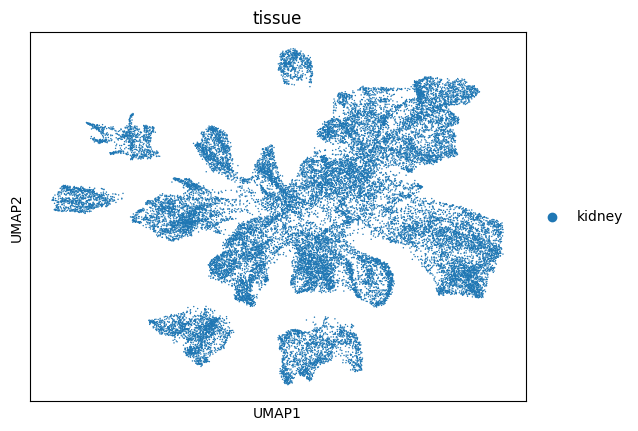

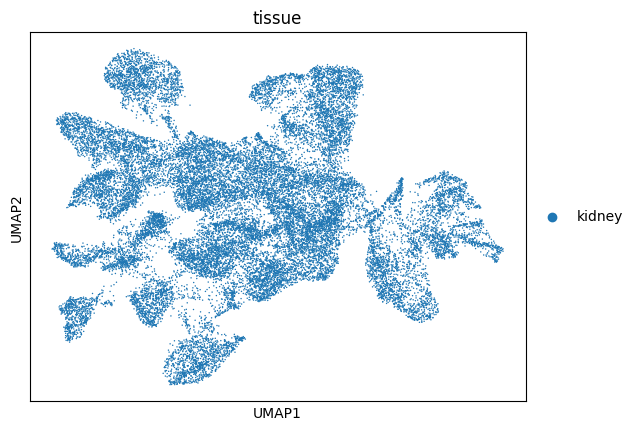

In [11]:
# Perform stratified subsampling based on batch
sample_frac = 0.01 # 1 percent subsample
random_state = 42
sampled_df = adata.obs.groupby(['dataset', 'batch'], group_keys=False).apply(
        lambda x: x.sample(frac=sample_frac, replace=False, random_state=random_state))
adata_subset = adata[sampled_df.index]
del(sampled_df)

label = 'tissue'
# Neighborhood embedding UMAP
sc.pp.neighbors(adata_subset,
                n_neighbors=15,
                use_rep='neighborhood_emb_layer_12',
                key_added='neighborhood')
sc.tl.umap(adata_subset,
           neighbors_key='neighborhood',
           key_added='neighborhood_umap')
adata_subset.obsm['X_umap'] = adata_subset.obsm['neighborhood_umap']
sc.pl.umap(adata_subset,
           neighbors_key='neighborhood',
           color=label)

# Cell embedding UMAP
sc.pp.neighbors(adata_subset,
                n_neighbors=15,
                use_rep='cell_emb_layer_12',
                key_added='cell')
sc.tl.umap(adata_subset,
           neighbors_key='cell',
           key_added='cell_umap')
adata_subset.obsm['X_umap'] = adata_subset.obsm['cell_umap']
sc.pl.umap(adata_subset,
           neighbors_key='cell',
           color=label)

In [32]:
import anndata as ad
import os

dataset_ids = ['1007']
adata_raw_list = []

# Load raw data
for subdir, _, files in os.walk(f'{silver_folder_path}/hst_corpus_80m'):
    if any(dataset_id in subdir.split('/')[-1].split('-')[0] for dataset_id in dataset_ids):
        print(f'Loading AnnData objects from {subdir}.')
        for file_idx, file in enumerate(files):
            if file.endswith('.h5ad'):
                file_path = os.path.join(subdir, file)
                adata_raw = sc.read_h5ad(file_path)
                adata_raw_list.append(adata_raw)     
concatenated_adata_raw = ad.concat(adata_raw_list, join='outer', index_unique=None)
concatenated_adata_raw.obs.index = concatenated_adata_raw.obs['cell_id']
del(concatenated_adata_raw.obs['cell_id'])

# Sort raw data
concatenated_adata_raw = concatenated_adata_raw[adata.obs_names, :].copy()

# Add embeddings
concatenated_adata_raw.obsm['cell_emb_layer_12'] = adata.obsm['cell_emb_layer_12']
concatenated_adata_raw.obsm['neighborhood_emb_layer_12'] = adata.obsm['neighborhood_emb_layer_12']

# Add metadata from original object
concatenated_adata_raw.obs['original_cell_id'] = concatenated_adata_raw.obs['batch'].astype(str) + concatenated_adata_raw.obs['original_cell_id'].astype(str)
daniyal_adata = sc.read_h5ad('/nfs/team361/dj17/RCC_Niches/artifacts/sample_integration/22032025_132909/model/RCC_20samples_afterclustering_withNiches.h5ad')

latent_cluster_key = 'nichecompass_cluster'
latent_leiden_resolution = 0.4

sc.pp.neighbors(daniyal_adata,
                n_neighbors=15,
                use_rep='nichecompass_latent',
                key_added='nichecompass_latent_connectivities')

sc.tl.leiden(daniyal_adata,
             neighbors_key='nichecompass_latent_connectivities',
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

daniyal_adata.obs['original_cell_id'] = daniyal_adata.obs['batch'].astype(str) + daniyal_adata.obs['cell_id'].astype(str)
obs_cols = [
    'original_cell_id',
    'level_1_cell_type',
    'level_2_cell_type',
    'level_3_cell_type',
    'SCVI_CLUSTERS_KEY',
    'nichecompass_cluster'
]
daniyal_adata.obs = daniyal_adata.obs[obs_cols]
concatenated_adata_raw.obs = concatenated_adata_raw.obs.merge(daniyal_adata.obs, on='original_cell_id', how='left')
#concatenated_adata_raw.obsm['nichecompass_latent'] = daniyal_adata.obsm['nichecompass_latent']
#concatenated_adata_raw.obsp['nichecompass_latent_connectivities'] = daniyal_adata.obsp['nichecompass_latent_connectivities']
#concatenated_adata_raw.obsp['nichecompass_latent_distances'] = daniyal_adata.obsp['nichecompass_latent_distances']
#concatenated_adata_raw.obsp['spatial_connectivities'] = daniyal_adata.obsp['spatial_connectivities']

# Write adata
concatenated_adata_raw.write(f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/adata_{read_checkpoint}_1007_annotated_new.h5ad')

Loading AnnData objects from /nfs/team361/sb75/DATASETS/silver/hst_corpus_80m/xhk1007-CV1-41b_1p.
Loading AnnData objects from /nfs/team361/sb75/DATASETS/silver/hst_corpus_80m/xhk1007-CV4-41b_1p.
Loading AnnData objects from /nfs/team361/sb75/DATASETS/silver/hst_corpus_80m/xhk1007-CV5-41b_1p.
Loading AnnData objects from /nfs/team361/sb75/DATASETS/silver/hst_corpus_80m/xhk1007-CV7-41b_1p.
Loading AnnData objects from /nfs/team361/sb75/DATASETS/silver/hst_corpus_80m/xhk1007-CV9-41b_1p.
Loading AnnData objects from /nfs/team361/sb75/DATASETS/silver/hst_corpus_80m/xhk1007-CV8-41b_1p.
Loading AnnData objects from /nfs/team361/sb75/DATASETS/silver/hst_corpus_80m/xhk1007-CV2-41b_1p.
Loading AnnData objects from /nfs/team361/sb75/DATASETS/silver/hst_corpus_80m/xhk1007-CV3-41b_1p.
Loading AnnData objects from /nfs/team361/sb75/DATASETS/silver/hst_corpus_80m/xhk1007-CV6-41b_1p.


/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [33]:
f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/adata_{read_checkpoint}_1007_annotated_new.h5ad'

'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_80m/11062025_183320_055/adata_ep10_0_1007_annotated_new.h5ad'

In [ ]:
layer = 12
write_to_disk = True
save_file_path = '' # TODO

if 'neighborhood_connectivities' not in adata.obsp.keys():
    # Compute UMAP representation for (aggregated) neighborhood gene embeddings
    sc.pp.neighbors(adata,
                    n_neighbors=15,
                    use_rep=f'neighborhood_emb_layer_{layer}',
                    key_added='neighborhood')

if 'neighborhood_umap' not in adata.obsm.keys():
    sc.tl.umap(adata,
               neighbors_key='neighborhood',
               key_added='neighborhood_umap')

    if write_to_disk:
        # Save adata
        adata.write(save_file_path)

if 'cell_connectivities' not in adata.obsp.keys():
    # Compute UMAP representation for (aggregated) cell gene embeddings
    sc.pp.neighbors(adata,
                    n_neighbors=15,
                    use_rep=f'cell_emb_layer_{layer}',
                    key_added='cell')
if 'cell_umap' not in adata.obsm.keys():
    sc.tl.umap(adata,
               neighbors_key='cell',
               key_added='cell_umap')

    if write_to_disk:
        # Save adata
        adata.write(save_file_path)

latent_leiden_resolution_neighborhood = 0.1 # TODO
latent_leiden_resolution_cell = 0.1 # TODO

sc.tl.leiden(adata,
             neighbors_key='neighborhood_connectivities',
             key_added='nemo_neighborhood_clusters',
             resolution=latent_leiden_resolution_neighborhood)

sc.tl.leiden(adata,
             neighbors_key='cell_connectivities',
             key_added='nemo_cell_clusters',
             resolution=latent_leiden_resolution_cell)

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/tmp/ipykernel_1467239/3441899431.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(daniyal_adata,


In [28]:
daniyal_adata.obs['nichecompass_cluster'] = daniyal_adata.obs['niche_name']

In [18]:
daniyal_adata.uns['nichecompass_latent_connectivities'] = ''

In [ ]:
adata_test.obs.columns

In [ ]:
adata_test.obs.head(5)

In [ ]:
adata = sc.read_h5ad(f'{artifacts_folder_path}/hst_corpus_70m/{load_timestamp}/adata_{read_checkpoint}_1007_annotated.h5ad')

In [ ]:
cell_type_key = 'level_1_cell_type'
spot_size = 20

In [ ]:
batch_ids = adata.obs['batch'].unique().tolist()

In [ ]:
adata_batch = adata[adata.obs['batch'] == 'CV1-KID-0-FO-1']

In [ ]:
batch_ids

In [ ]:
sc.pl.spatial(adata_batch,
              color=cell_type_key,
              #palette=custom_palette,
              spot_size=spot_size,
              #save=f'{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg'
             )

In [ ]:
adata_batch = adata[adata.obs['batch'] == 'CV1-KID-0-FO-1']

In [ ]:
sc.pl.spatial(adata_batch,
              color=cell_type_key,
              #palette=custom_palette,
              spot_size=spot_size,
              #save=f'{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg'
             )

In [ ]:
import os

In [ ]:
dataset_ids = ['1007']

In [ ]:


# Load raw data
for subdir, _, files in os.walk(f'{silver_folder_path}/hst_corpus_70m'):
    if any(dataset_id in subdir.split('/')[-1].split('-')[0] for dataset_id in dataset_ids):
        print(f'Loading AnnData objects from {subdir}.')
        for file_idx, file in enumerate(files):
            if file.endswith('.h5ad'):
                file_path = os.path.join(subdir, file)
                adata_raw = sc.read_h5ad(file_path)
                print(adata_raw.obs.head(1))
                print(adata_raw)

In [ ]:
adata_raw